# **Business Context:**

Pneumonia is one of the leading causes of morbidity and mortality worldwide, particularly affecting children under five years and elderly populations. According to the World Health Organization (WHO), pneumonia accounts for a significant percentage of deaths caused by infectious diseases. Early detection and timely treatment are critical to improving patient outcomes, yet current diagnostic methods present challenges.

The most common method for diagnosing pneumonia is through clinical evaluation combined with chest X-ray imaging. However, accurate interpretation of X-rays requires skilled radiologists, whose availability is limited in many regions, especially in rural or resource-constrained healthcare settings. Even when radiologists are available, factors such as fatigue, high patient load, and human error can affect the accuracy and consistency of diagnosis. This may lead to delayed treatment, misdiagnosis, or unnecessary use of antibiotics, worsening patient outcomes and straining healthcare systems.

With the advancement of machine learning and deep learning, automated image analysis has emerged as a promising solution to support medical imaging tasks. Leveraging large datasets of chest X-ray images, AI- driven approaches can be trained to recognize pneumonia-related abnormalities in the lungs with high accuracy and consistency. Such systems can serve as decision-support tools for healthcare professionals, reducing diagnostic workload, improving accuracy, and providing timely interventions, particularly in areas with limited medical expertise.

# **Objective:**

The main objective of this project is to develop an intelligent, automated system capable of detecting pneumonia from chest X-ray images using machine learning and deep learning techniques. The system should aim to:

1. Accurately classify chest X-ray images into pneumonia-positive and pneumonia-negative cases.
2. Assist healthcare professionals by providing a reliable second opinion that reduces diagnostic
errors and variability.
3. Improve efficiency by delivering faster diagnoses, enabling timely treatment, and reducing the
burden on radiologists.
4. Enhance accessibility by offering a scalable solution that can be deployed in hospitals, clinics, or
rural healthcare centers with limited resources.
5. Support global health efforts by contributing to early detection, lowering pneumonia-related mortality rates, and optimizing antibiotic usage.

Ultimately, the solution aims to bridge the gap between limited medical expertise and growing healthcare demands, making pneumonia diagnosis more accurate, efficient, and accessible worldwide.

# **Data Description:**

In the dataset, some of the features are labeled “Not Normal No Lung Opacity”. This extra third class
indicates that while pneumonia was determined not to be present, there was nonetheless some type of abnormality on the image and oftentimes this finding may mimic the appearance of true pneumonia.Dicom original images: - Medical images are stored in a special format called DICOM files (*.dcm). They contain a combination of header metadata as well as underlying raw image arrays for pixel data

# **Installing Necessery Pacakages**

In [ ]:
!pip install tensorstore>=0.1.71
!pip install tensorflow
!pip install tensorflow-decision-forests
!pip install tf-keras
!pip install tensorflow
!pip install tensorflow-text
!pip install ml-dtypes>=0.5.0
!pip install tensorflow[and-cuda] numpy -q
!pip install pydicom
!pip install pydicom pillow scikit-image opencv-python matplotlib
!pip install mlflow==3.0.1 pyngrok==7.2.12 -q

INFO: pip is looking at multiple versions of tf-keras to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 68.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 75.9 MB/s eta 0:00:00
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.20.0
    Uninstalling tensorboard-2.20.0:
      Successfully uninstalled tensorboard-2.20.0
  Attempting uninstall: tensorflow
    Found existing installation: tensorflow 2.20.0
    Uninstalling tensorflow-2.20.0:
      Successfully uninstalled tensorflow-2.20.0
  Attempting uninstall: tf_keras
    Found existing installation: tf_keras 2.20.0
    Uninstalling tf_keras-2.20.0:
      Successfully uninstalled tf_keras-2.20.0
ERROR: pip's dependency resolver 

# **Importing Header Files**

In [ ]:
import os
import pydicom
import zipfile
import numpy as np
import pandas as pd
import shutil
from PIL import Image
import matplotlib.pyplot as plt
import math
import cv2
import seaborn as sns
import time
import subprocess
import mlflow
import re
from pyngrok import ngrok
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import Sequence
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Dense, Dropout,
    Flatten, BatchNormalization, Activation,
    GlobalAveragePooling2D
)
from tensorflow.keras.optimizers import Adam, SGD, Adagrad, RMSprop
from tensorflow.keras.applications.vgg16 import VGG16 # Fixed: Route through tf.keras
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow
from sklearn.metrics import (confusion_matrix, f1_score, accuracy_score,
                             recall_score, precision_score, classification_report,
                             mean_squared_error as mse)
import warnings
warnings.filterwarnings('ignore')

In [ ]:
tf.keras.utils.set_random_seed(812)
tf.config.experimental.enable_op_determinism()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Data Overview**

**Importing the data**

In [ ]:
image = '/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 12 : Capstone Project /stage_2_train_images.zip'
images = image

test_images = '/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 12 : Capstone Project /stage_2_test_images.zip'
t_images = test_images

stage_2_train_labels = pd.read_csv('/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 12 : Capstone Project /stage_2_train_labels.csv')
labels = stage_2_train_labels.copy()

stage_2_detailed_class_info = pd.read_csv("/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 12 : Capstone Project /stage_2_detailed_class_info.csv")
class_info = stage_2_detailed_class_info.copy()

In [ ]:
#extracting training images
with zipfile.ZipFile(images, 'r') as zip_ref:
    zip_ref.extractall('/content/extracted_Train_images')

os.listdir('/content/extracted_Train_images')

['__MACOSX', 'stage_2_train_images']

In [ ]:
image_dir = '/content/extracted_Train_images/stage_2_train_images'

# Count all image files recursively
image_extensions = ('.dcm')

image_files = []
for root, dirs, files in os.walk(image_dir):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(file))

print("Total number of images:", len(image_files))


Total number of images: 26684


In [ ]:
#Extracting Testing images
with zipfile.ZipFile(t_images, 'r') as zip_ref:
    zip_ref.extractall('/content/extracted_Test_images')

os.listdir('/content/extracted_Test_images')

['__MACOSX', 'stage_2_test_images']

In [ ]:
test_image_dir = '/content/extracted_Test_images/stage_2_test_images'

image_extensions = ('.dcm')

test_image_files = []
for root, dirs, files in os.walk(test_image_dir):
    for file in files:
        if file.lower().endswith(image_extensions):
            test_image_files.append(os.path.join(root, file))

print("Total number of images:", len(test_image_files))

Total number of images: 3000


Merging **class_info.csv** file and **labels.csv** file using patientid to create new csv file

In [ ]:
print(f"Total number of rows in stage_2_train_labels: {labels.shape[0]}")
print(f"Total number of column in stage_2_train_labels: {labels.shape[1]}")


Total number of rows in stage_2_train_labels: 30227
Total number of column in stage_2_train_labels: 4


In [ ]:
labels.head()

,patientId,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,213.0,379.0,1


In [ ]:
labels.tail()

,patientId,width,height,Target
30222,c1ec14ff-f6d7-4b38-b0cb-fe07041cbdc8,228.0,379.0,1
30223,c1edf42b-5958-47ff-a1e7-4f23d99583ba,NaN,NaN,0
30224,c1f6b555-2eb1-4231-98f6-50a963976431,NaN,NaN,0
30225,c1f7889a-9ea9-4acb-b64c-b737c929599a,261.0,345.0,1
30226,c1f7889a-9ea9-4acb-b64c-b737c929599a,201.0,356.0,1


In [ ]:
print(f"Total rows in stage_2_detailed_class_info: {class_info.shape[0]}")
print(f"Total columns in stage_2_detailed_class_info: {class_info.shape[1]}")

Total rows in stage_2_detailed_class_info: 30227
Total columns in stage_2_detailed_class_info: 2


In [ ]:
class_info.head()

,patientId,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,Lung Opacity


In [ ]:
PneumoDet = pd.merge(class_info, labels,on="patientId", how="inner")
print(f"Merged file saved! Total rows: {len(PneumoDet)}")
print("The total number of rows in the Pneumonia Detection are: ",PneumoDet.shape[0])
print("The total number of columns in the Pneumonia Detection are: ",PneumoDet.shape[1])

Merged file saved! Total rows: 37629
The total number of rows in the Pneumonia Detection are:  37629
The total number of columns in the Pneumonia Detection are:  5


In [ ]:
duplicate = PneumoDet[PneumoDet['patientId'].duplicated()]
PneumoDet = PneumoDet.drop(duplicate.index)
PneumoDet.to_csv("PneumoDet.csv", index=False)
print(f"The total number of rows in the Pneumonia Detection are: ", PneumoDet.shape[0])
print(f"The total number of columns in the Pneumonia Detection are: ", PneumoDet.shape[1])

The total number of rows in the Pneumonia Detection are:  26684
The total number of columns in the Pneumonia Detection are:  5


In [ ]:
pd = pd.read_csv("PneumoDet.csv")
print(f"Total rows in CSV: {pd.shape[0]}")
print(f"Total columns in CSV: {pd.shape[1]}")

Total rows in CSV: 26684
Total columns in CSV: 5


In [ ]:
pd.head()

,patientId,class,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,No Lung Opacity / Not Normal,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,No Lung Opacity / Not Normal,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,Normal,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,Lung Opacity,213.0,379.0,1


**Check the shape of the data**

In [ ]:
print(f"Number of files: {len(image_files)}\n")
print(f"The total number of rows in PneumoDet.csv file are : {PneumoDet.shape[0]}")
print(f"The total number of columns in PneumoDet.csv file are : {PneumoDet.shape[1]}\n")
print(f"The columns which are present in PneumoDet.csv file are : {list(PneumoDet.columns)}\n")
print(f"The data type which are present in PneumoDet.csv file are : {list(PneumoDet.dtypes)}\n")

Number of files: 26684

The total number of rows in PneumoDet.csv file are : 26684
The total number of columns in PneumoDet.csv file are : 5

The columns which are present in PneumoDet.csv file are : ['patientId', 'class', 'width', 'height', 'Target']

The data type which are present in PneumoDet.csv file are : [dtype('O'), dtype('O'), dtype('float64'), dtype('float64'), dtype('int64')]



dtype('O') Means Object (String) Data Type which means the columns contain strings (text data) instead of numbers. This is common for image file paths and class labels.

# **Exploratory Data Analysis**

Ploting random images from each class and printing their corresponding labels

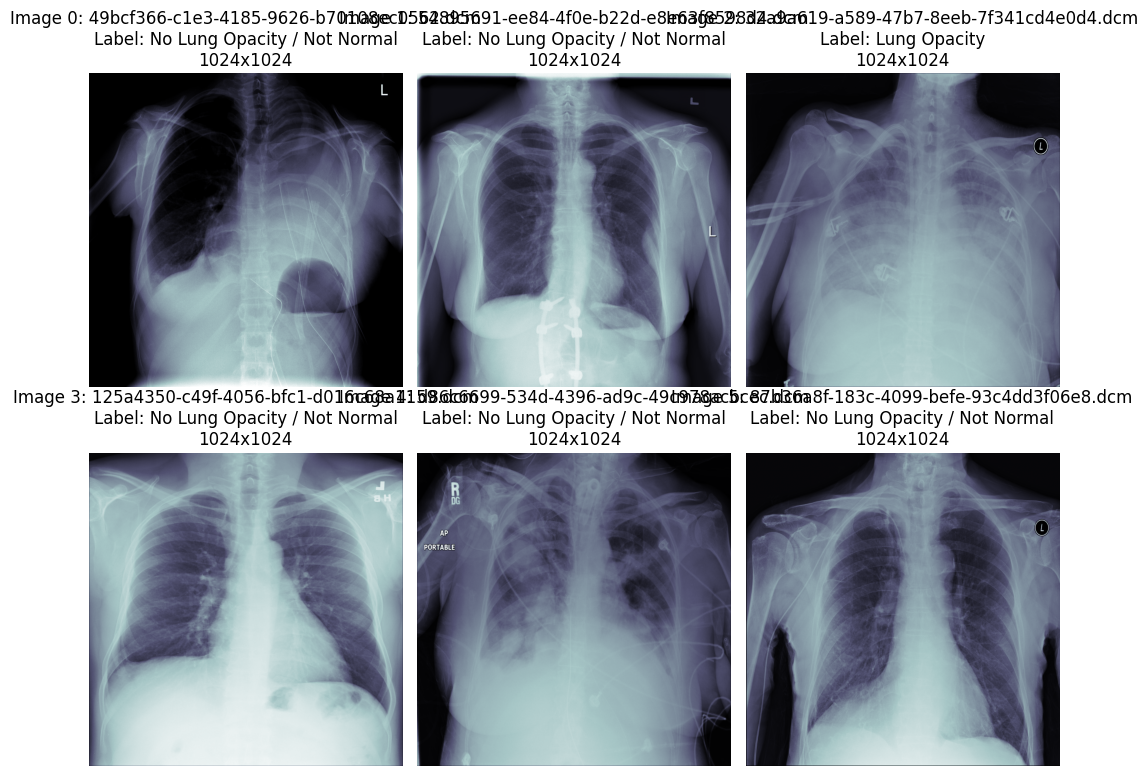

In [ ]:
import pandas as pd
folder_path1 = '/content/extracted_Train_images/stage_2_train_images'
files = os.listdir(folder_path1)

dcm_files = [f for f in files if os.path.isfile(os.path.join(folder_path1, f)) and not f.endswith('.csv')]

DF = pd.read_csv('/content/PneumoDet.csv')

label_dict = dict(zip(DF['patientId'], DF['class']))

num_images = min(6, len(dcm_files))
fig, axes = plt.subplots(2, 3, figsize=(10, 8))
axes = axes.flatten()

for n in range(num_images):
    file_path = os.path.join(folder_path1, dcm_files[n])
    ds = pydicom.dcmread(file_path)
    shape = ds.pixel_array.shape

    patient_id = ds.get('PatientID', '').replace('.', '')
    label = label_dict.get(patient_id, label_dict.get(dcm_files[n], "Unknown"))

    #print(f"Image {n}: {dcm_files[n]} | PatientID: {patient_id} | Label: {label} | Dimensions: {shape[0]}x{shape[1]}")
    axes[n].imshow(ds.pixel_array, cmap=plt.cm.bone)
    axes[n].set_title(f"Image {n}: {dcm_files[n]}\nLabel: {label}\n{shape[0]}x{shape[1]}")
    axes[n].axis('off')

plt.tight_layout()
plt.show()

**Check for class imbalance**

class
No Lung Opacity / Not Normal    11821
Normal                           8851
Lung Opacity                     6012
Name: count, dtype: int64


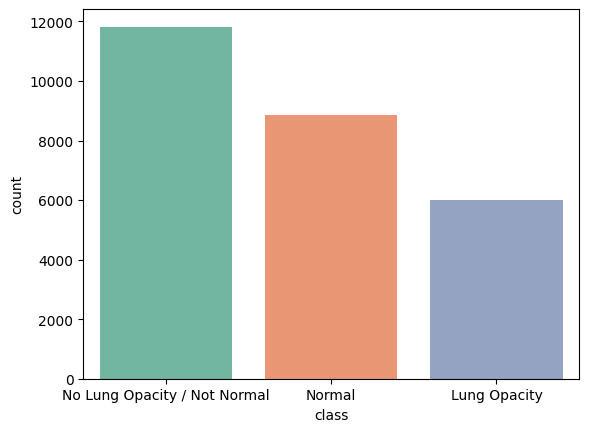

In [ ]:
Class_count = PneumoDet['class'].value_counts()
print(Class_count)

sns.countplot(x='class', data=PneumoDet, palette='Set2')
plt.show()

Why this matters for model:

The "No Lung Opacity / Not Normal" class is the hardest for a neural network to get right. Because these images contain abnormalities (like fluid or a huge heart shadow) so model will often misclassify them as "Lung Opacity" (Pneumonia), actually they are not having "Lung Opacity" (Pneumonia).

In that case here I will replace "No Lung Opacity / Not Normal" with "Normal" because here we are designing a model to predict the patient has Pneumonia or not based upon x-ray image.

In [ ]:
PneumoDet['class'] = PneumoDet['class'].replace("No Lung Opacity / Not Normal", "Normal")

class
Normal          20672
Lung Opacity     6012
Name: count, dtype: int64


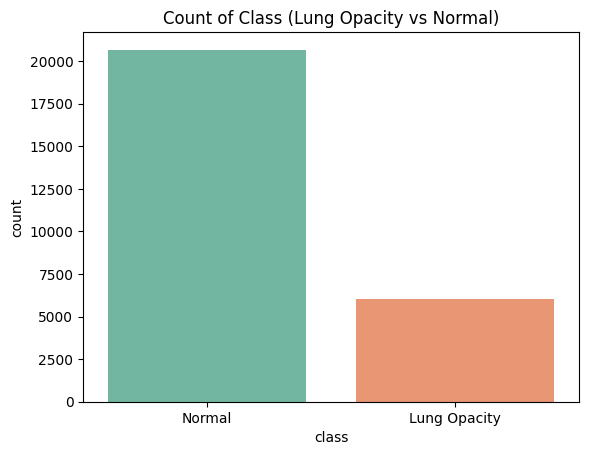

In [ ]:
Class_count = PneumoDet['class'].value_counts()
print(Class_count)

sns.countplot(x='class', data=PneumoDet, palette='Set2');
plt.title('Count of Class (Lung Opacity vs Normal)')
plt.show()

Target
0    20672
1     6012
Name: count, dtype: int64


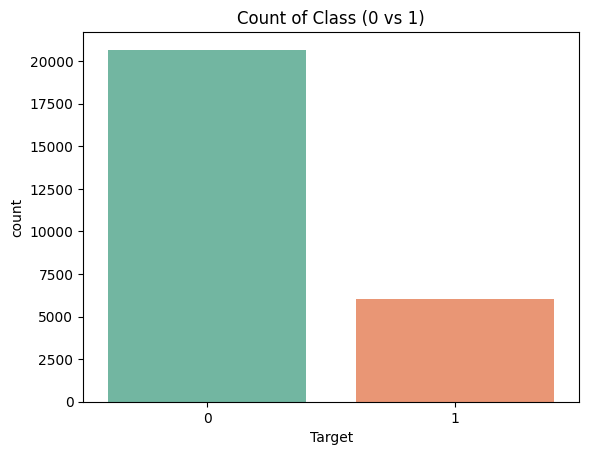

In [ ]:
Class_Imbalance = PneumoDet['Target'].value_counts()
print(Class_Imbalance)

sns.countplot(x='Target', data=PneumoDet, palette='Set2')
plt.title('Count of Class (0 vs 1)')
plt.show()

# **Data Preprocessing**

In this code it's safe because:

Doing normalization before splitting is actually fine here, because Normalization here is just / 255.0 — a fixed mathematical operation, not learned from data. It doesn't use any statistics (mean, std) calculated from the training set. So applying it to all images before splitting causes no data leakage.

Resizing and Appling the normalization to the image

In [ ]:
input_folder  = '/content/extracted_Train_images/stage_2_train_images'
output_folder = '/content/resized_images'
norm_folder   = '/content/normalized_images'
size = (256, 256)

if os.path.exists(output_folder):
    shutil.rmtree(output_folder)
os.makedirs(output_folder, exist_ok=True)

if os.path.exists(norm_folder):
    shutil.rmtree(norm_folder)
os.makedirs(norm_folder, exist_ok=True)

count = 0

for filename in os.listdir(input_folder):
    if filename.lower().endswith('.dcm'):
        file_path = os.path.join(input_folder, filename)
        ds = pydicom.dcmread(file_path)
        ds.decompress()
        arr = ds.pixel_array

        # Step 1: Resize
        resized = cv2.resize(arr, size, interpolation=cv2.INTER_LINEAR)

        # Step 2: Save resized DICOM
        ds.PixelData = resized.astype(arr.dtype).tobytes()
        ds.Rows, ds.Columns = resized.shape[:2]
        ds.save_as(os.path.join(output_folder, filename))

        # Step 3: Normalize [0, 1] and save as .npy
        arr_min, arr_max = resized.min(), resized.max()
        normalized = (resized.astype(np.float32) - arr_min) / (arr_max - arr_min + 1e-8)
        npy_name   = filename.replace('.dcm', '.npy')
        np.save(os.path.join(norm_folder, npy_name), normalized)

        count += 1

print(f"✓ Resized  {count} images → {output_folder}")
print(f"✓ Normalized {count} images → {norm_folder}")

✓ Resized  26684 images → /content/resized_images
✓ Normalized 26684 images → /content/normalized_images


Verify a sample

In [ ]:
sample     = os.listdir(norm_folder)[0]
sample_img = np.load(os.path.join(norm_folder, sample))
print(f"\nSample: {sample}")
print(f"  Shape : {sample_img.shape}")
print(f"  Min   : {sample_img.min():.4f}")
print(f"  Max   : {sample_img.max():.4f}")
print(f"  Dtype : {sample_img.dtype}")


Sample: f6b51ab0-d1b0-4fbb-8b6e-3acc0464b055.npy
  Shape : (256, 256)
  Min   : 0.0000
  Max   : 1.0000
  Dtype : float64


Spliting the dataset into train, validation and test

In [ ]:
PneumoDet = pd.read_csv("PneumoDet.csv")
PneumoDet['image_name'] = PneumoDet['patientId'].astype(str).str.strip() + '.dcm'

existing_files = set(os.listdir(output_folder))
PneumoDet_filtered = PneumoDet[PneumoDet['image_name'].isin(existing_files)].reset_index(drop=True)
print(f"Total images: {len(PneumoDet['image_name'])}")
print(f"Shape: {PneumoDet['image_name'].shape}")
print(f"Matched: {len(PneumoDet_filtered)} | Yes: {sum(PneumoDet_filtered['Target']==1)} | No: {sum(PneumoDet_filtered['Target']==0)}")


X = PneumoDet_filtered['image_name'].tolist()
y = PneumoDet_filtered['Target'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

y_train = pd.Series(y_train).reset_index(drop=True)
y_val   = pd.Series(y_val).reset_index(drop=True)
y_test  = pd.Series(y_test).reset_index(drop=True)

Total images: 26684
Shape: (26684,)
Matched: 26684 | Yes: 6012 | No: 20672


In [ ]:
sample_file = os.path.join(output_folder, PneumoDet['image_name'][0])
ds = pydicom.dcmread(sample_file)
print(f"Image size: {ds.Rows} x {ds.Columns}")

Image size: 256 x 256


Verification

In [ ]:
df_train = pd.DataFrame({
    "image_name": X_train,
    "patientid":  [f.replace('.dcm', '') for f in X_train],
    "Target":     y_train.values
})

# Cross-check first 3 rows against original CSV
print("\nVerification:")
for _, row in df_train.head().iterrows():
    csv_label = PneumoDet[PneumoDet['patientId'] == row['patientid']]['Target'].values[0]
    match = '✅' if csv_label == row['Target'] else '❌'
    print(f"  {match} {row['patientid']}  split={row['Target']}  csv={csv_label}")


Verification:
  ✅ 8e6e3560-41b4-40ad-9cf8-0c51628bde2b  split=1  csv=1
  ✅ 05f88159-8c6e-4d9a-92a8-a20c6fb2930d  split=0  csv=0
  ✅ fa7af4c7-4c35-48b6-bf91-585da33e4b6e  split=0  csv=0
  ✅ a1a1b826-0de6-4d0f-b082-2eec1c456944  split=1  csv=1
  ✅ 56419e8d-5982-460c-9e71-546609e6ebd7  split=0  csv=0


Convert the RGB images to Grayscale

No conversion needed, Already grayscale

The image is already in grayscale format (typical for CT/X-ray). The DICOM image was already 2D (single channel), not RGB

So Ploting the images before and after the pre-processing steps is unnecessary

    Reason         
      * No visual difference : Grayscale images look identical before/after conversion (they're already grayscale)
      * Same data : arr and gray contain the same pixel values
      * Wasted computation : cv2.cvtColor() isn't even being called
      * Common for medical images : 99% of CT/X-ray/MRI DICOM files are already grayscale

In [ ]:
flat_folder = '/content/flat_images'
if os.path.exists(flat_folder):
    shutil.rmtree(flat_folder)
os.makedirs(flat_folder, exist_ok=True)

def save_flat_images(file_list, norm_folder, flat_folder, batch_size=500):
    total = len(file_list)
    for i in range(0, total, batch_size):
        batch = file_list[i:i + batch_size]
        for fname in batch:
            img      = np.load(os.path.join(norm_folder, fname.replace('.dcm', '.npy')))
            flat     = img.flatten().astype(np.float32)
            out_name = fname.replace('.dcm', '_flat.npy')
            np.save(os.path.join(flat_folder, out_name), flat)

        print(f"  Batch {i//batch_size + 1} ({min(i+batch_size, total)}/{total})")
    print(f"✓ Saved {total} flat files → {flat_folder}")

print("Saving flat images to disk...")
save_flat_images(X_train, norm_folder, flat_folder)

Saving flat images to disk...
  Batch 1 (500/18678)
  Batch 2 (1000/18678)
  Batch 3 (1500/18678)
  Batch 4 (2000/18678)
  Batch 5 (2500/18678)
  Batch 6 (3000/18678)
  Batch 7 (3500/18678)
  Batch 8 (4000/18678)
  Batch 9 (4500/18678)
  Batch 10 (5000/18678)
  Batch 11 (5500/18678)
  Batch 12 (6000/18678)
  Batch 13 (6500/18678)
  Batch 14 (7000/18678)
  Batch 15 (7500/18678)
  Batch 16 (8000/18678)
  Batch 17 (8500/18678)
  Batch 18 (9000/18678)
  Batch 19 (9500/18678)
  Batch 20 (10000/18678)
  Batch 21 (10500/18678)
  Batch 22 (11000/18678)
  Batch 23 (11500/18678)
  Batch 24 (12000/18678)
  Batch 25 (12500/18678)
  Batch 26 (13000/18678)
  Batch 27 (13500/18678)
  Batch 28 (14000/18678)
  Batch 29 (14500/18678)
  Batch 30 (15000/18678)
  Batch 31 (15500/18678)
  Batch 32 (16000/18678)
  Batch 33 (16500/18678)
  Batch 34 (17000/18678)
  Batch 35 (17500/18678)
  Batch 36 (18000/18678)
  Batch 37 (18500/18678)
  Batch 38 (18678/18678)
✓ Saved 18678 flat files → /content/flat_images


In [ ]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
import numpy as np

#appling oversampling and undersampling on X_train
indices = np.arange(len(X_train)).reshape(-1, 1)

# Step 1: Oversample minority (Yes: 4208 → 9000)
ros = RandomOverSampler(sampling_strategy={1: 9000, 0: 14470}, random_state=42)
indices_over, y_over = ros.fit_resample(indices, y_train)

# Step 2: Undersample majority (No: 14470 → 9000)
rus = RandomUnderSampler(sampling_strategy={0: 9000, 1: 9000}, random_state=42)
indices_bal, y_bal = rus.fit_resample(indices_over, y_over)
indices_bal = indices_bal.flatten()

print(f"After : {len(indices_bal)} samples")
print(f"length of X_train Yes={sum(y_bal==1)} | length of X_train No={sum(y_bal==0)}")

#appling oversampling and undersampling on X_Val
val_indices = np.arange(len(X_val)).reshape(-1, 1)

rus_val = RandomUnderSampler(sampling_strategy='auto', random_state=42)
val_indices_bal, y_val_bal = rus_val.fit_resample(val_indices, y_val)

val_indices_bal = val_indices_bal.flatten()

X_val_balanced = [X_val[i] for i in val_indices_bal]
y_val_balanced = y_val_bal.astype(np.int32).tolist()

print(f"Balanced val → Normal: {sum(y_val_bal==0)} | Pneumonia: {sum(y_val_bal==1)}")


After : 18000 samples
length of X_train Yes=9000 | length of X_train No=9000
Balanced val → Normal: 902 | Pneumonia: 902


### Utility functions

In [ ]:
def model_performance_classification(model, predictors, target):
    pred = model.predict(predictors).reshape(-1) > 0.5
    target = target.reshape(-1)
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred, average='weighted')
    precision = precision_score(target, pred, average='weighted')
    f1 = f1_score(target, pred, average='weighted')

    # Create dataframe
    df_perf = pd.DataFrame({
        "Accuracy": acc,
        "Recall": recall,
        "Precision": precision,
        "F1 Score": f1
    }, index=[0])

    return df_perf

In [ ]:
def plot_confusion_matrix(model,predictors,target,ml=False):
    """
    Function to plot the confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    ml: To specify if the model used is an sklearn ML model or not (True means ML model)
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)

    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(target,pred)
    f, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        confusion_matrix,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax
    )
    plt.show()

# **Model Building**

##Define a CNN model from scratch

Base model

In [ ]:

tf.keras.backend.clear_session()
model_1 = Sequential([
    Conv2D(32, (3,3), padding='same', input_shape=(256,256,1)),
    BatchNormalization(), Activation('relu'),
    MaxPooling2D((2,2)), Dropout(0.2),

    Conv2D(64, (3,3), padding='same'),
    BatchNormalization(), Activation('relu'),
    MaxPooling2D((2,2)), Dropout(0.2),

    Conv2D(128, (3,3), padding='same'),
    BatchNormalization(), Activation('relu'),
    MaxPooling2D((2,2)), Dropout(0.3),

    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model_1.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='Precision'),
             tf.keras.metrics.Recall(name='Recall')]
)


In [ ]:
BATCH_SIZE = 64
AUTOTUNE   = tf.data.AUTOTUNE
IMG_SIZE   = 256

balanced_files  = [X_train[i] for i in indices_bal]
balanced_labels = y_bal.astype(np.int32).tolist()


def load_image(fname, label):
    fname    = fname.numpy().decode('utf-8')
    npy_name = fname.replace('.dcm', '.npy')
    img      = np.load(os.path.join(norm_folder, npy_name)).astype(np.float32)
    img      = img.reshape(IMG_SIZE, IMG_SIZE, 1)
    return img, label

def tf_load_image(fname, label):
    img, label = tf.py_function(load_image, [fname, label], [tf.float32, tf.int32])
    img.set_shape([IMG_SIZE, IMG_SIZE, 1])
    label.set_shape([])
    return img, label

def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.1)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

train_ds = (tf.data.Dataset.from_tensor_slices((balanced_files, balanced_labels))
            .shuffle(len(balanced_files), seed=42)
            .map(tf_load_image, num_parallel_calls=AUTOTUNE)
            .map(augment, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

val_ds = (tf.data.Dataset.from_tensor_slices((X_val_balanced, y_val_balanced))
          .map(tf_load_image, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_AUC',
        patience=4,
        mode='max',
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        mode='min',
        verbose=1
    )
]

In [ ]:
history = model_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    verbose=2,
    callbacks=callbacks
    )


Epoch 1/15
282/282 - 234s - 830ms/step - Precision: 0.6003 - Recall: 0.5864 - accuracy: 0.5979 - loss: 0.7313 - val_Precision: 0.5000 - val_Recall: 1.0000 - val_accuracy: 0.5000 - val_loss: 0.9238 - learning_rate: 1.0000e-04
Epoch 2/15
282/282 - 212s - 753ms/step - Precision: 0.6312 - Recall: 0.6359 - accuracy: 0.6322 - loss: 0.6875 - val_Precision: 0.4989 - val_Recall: 0.9956 - val_accuracy: 0.4978 - val_loss: 0.9806 - learning_rate: 1.0000e-04
Epoch 3/15
282/282 - 214s - 758ms/step - Precision: 0.6379 - Recall: 0.6554 - accuracy: 0.6417 - loss: 0.6664 - val_Precision: 0.5425 - val_Recall: 0.9490 - val_accuracy: 0.5743 - val_loss: 0.7750 - learning_rate: 1.0000e-04
Epoch 4/15
282/282 - 210s - 745ms/step - Precision: 0.6590 - Recall: 0.6664 - accuracy: 0.6608 - loss: 0.6438 - val_Precision: 0.5272 - val_Recall: 0.9579 - val_accuracy: 0.5493 - val_loss: 1.0018 - learning_rate: 1.0000e-04
Epoch 5/15

Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
282/282 - 20

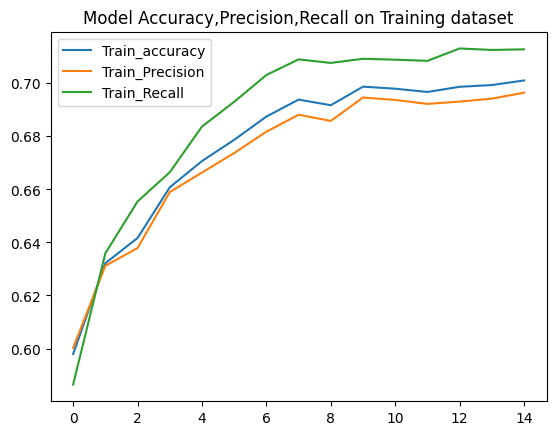

In [ ]:
plt.plot(history.history['accuracy'], label='Train_accuracy')
plt.plot(history.history['Precision'], label='Train_Precision')
plt.plot(history.history['Recall'], label='Train_Recall')
plt.title('Model Accuracy,Precision,Recall on Training dataset')
plt.legend()
plt.show()


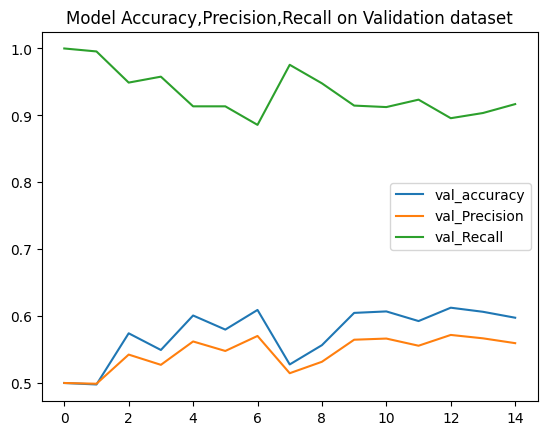

In [ ]:
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.plot(history.history['val_Precision'], label='val_Precision')
plt.plot(history.history['val_Recall'], label='val_Recall')
plt.title('Model Accuracy,Precision,Recall on Validation dataset')
plt.legend()
plt.show()


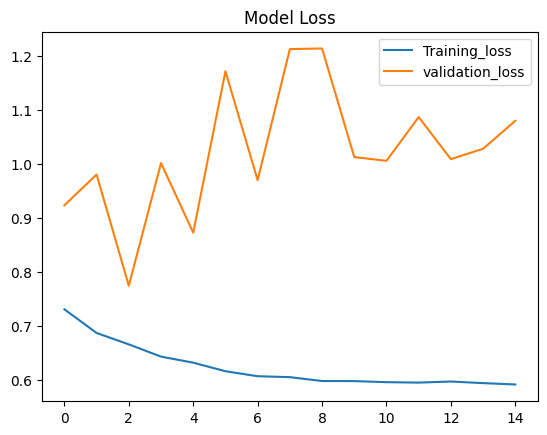

In [ ]:
plt.plot(history.history['loss'], label='Training_loss')
plt.plot(history.history['val_loss'], label='validation_loss')
plt.title('Model Loss')
plt.legend()
plt.show()

Check and comment on the performance of the model

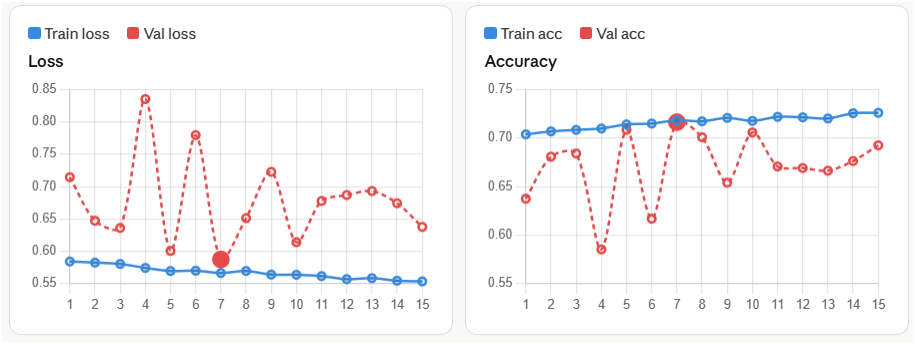


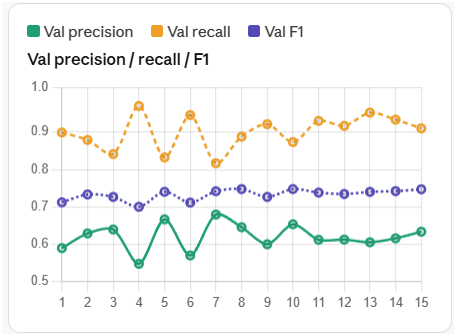


Initially the model contains 15 epochs but Epoch 07 is actually the most reliable checkpoint for pneumonia detection because

    It wins on every metric simultaneously

      * lowest  val_loss 0.5877
      * highest val_accuracy 0.716
      * highest val_precision 0.680
      * highest val_F1 0.743


Every epoch after 7 is worse on val_loss and F1, confirming the model peaked there and overfit from Epoch 8 onward.

Epochs 1–6 — slow, unstable climb. The model starts much better than the previous run (no prediction collapse this time — Epoch 1 val_precision is already 0.59), but val_loss still oscillates badly. Epochs 4 and 6 are clear regressions where val_loss spikes to 0.835 and 0.779 respectively.

***Epoch 7 — the sweet spot. Both val_loss and val_accuracy peak together, which is rare and reliable signal. Val_recall of 0.817 means the model misses about 1 in 5 real pneumonia cases — acceptable but still room to improve.***

Epochs 8–15 — overfitting. Train accuracy continues climbing (0.717 → 0.726) while val metrics oscillate without improving.

# **Transfer Learning**

## Appling transfer learning using pre-trained CNN models

model 1: VGG16 (Simple, strong baseline)

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.backend.clear_session()

base_train_ds = (tf.data.Dataset.from_tensor_slices((balanced_files, balanced_labels))
            .shuffle(len(balanced_files), seed=42)
            .map(tf_load_image, num_parallel_calls=tf.data.AUTOTUNE)
            .map(augment, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

base_val_ds = (tf.data.Dataset.from_tensor_slices((X_val_balanced, y_val_balanced))
          .map(tf_load_image, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))


def preprocess_for_vgg(image, label):
    image = tf.image.grayscale_to_rgb(image)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label


train_ds = base_train_ds.map(preprocess_for_vgg, num_parallel_calls=tf.data.AUTOTUNE)
val_ds   = base_val_ds.map(preprocess_for_vgg,   num_parallel_calls=tf.data.AUTOTUNE)


base_model = VGG16(weights='imagenet', include_top=False, input_shape=(256,256,3))
base_model.trainable = False

model_vgg = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model_vgg.compile(
    optimizer=optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='Precision'),
        tf.keras.metrics.Recall(name='Recall')
    ]
)

model_vgg.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 8, 8, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,993 (56.39 MB)

 Trainable params: 66,049 (258.00 KB)

 Non-trainable params: 14,714,944 (56.13 MB)

In [ ]:
history_vgg = model_vgg.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=2,

)

Epoch 1/5
282/282 - 294s - 1s/step - Precision: 0.5449 - Recall: 0.6181 - accuracy: 0.5509 - loss: 0.6930 - val_Precision: 0.5000 - val_Recall: 1.0000 - val_accuracy: 0.5000 - val_loss: 0.9900
Epoch 2/5
282/282 - 279s - 988ms/step - Precision: 0.6056 - Recall: 0.7027 - accuracy: 0.6226 - loss: 0.6627 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 0.9086
Epoch 3/5
282/282 - 275s - 973ms/step - Precision: 0.6190 - Recall: 0.7286 - accuracy: 0.6401 - loss: 0.6559 - val_Precision: 0.6579 - val_Recall: 0.0277 - val_accuracy: 0.5067 - val_loss: 0.7145
Epoch 4/5
282/282 - 277s - 983ms/step - Precision: 0.6264 - Recall: 0.7157 - accuracy: 0.6444 - loss: 0.6513 - val_Precision: 0.6935 - val_Recall: 0.3914 - val_accuracy: 0.6092 - val_loss: 0.6521
Epoch 5/5
282/282 - 278s - 986ms/step - Precision: 0.6315 - Recall: 0.7248 - accuracy: 0.6509 - loss: 0.6458 - val_Precision: 1.0000 - val_Recall: 0.0011 - val_accuracy: 0.5006 - val_loss: 0.9807


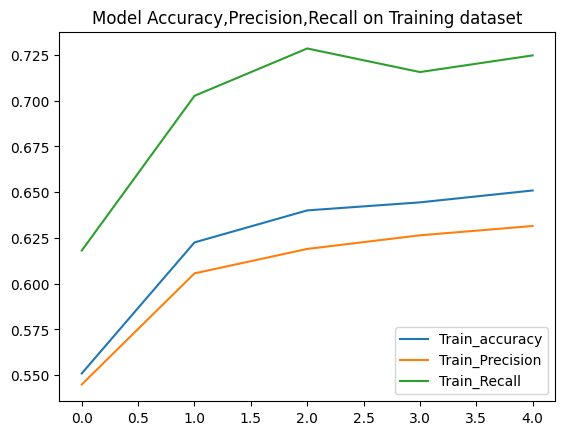

In [ ]:
plt.plot(history_vgg.history['accuracy'], label='Train_accuracy')
plt.plot(history_vgg.history['Precision'], label='Train_Precision')
plt.plot(history_vgg.history['Recall'], label='Train_Recall')
plt.title('Model Accuracy,Precision,Recall on Training dataset')
plt.legend()
plt.show()

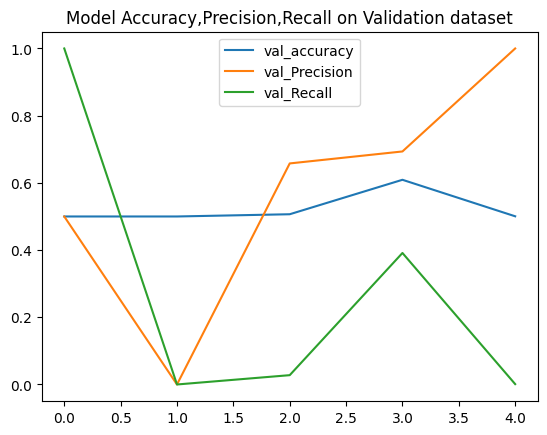

In [ ]:
plt.plot(history_vgg.history['val_accuracy'], label='val_accuracy')
plt.plot(history_vgg.history['val_Precision'], label='val_Precision')
plt.plot(history_vgg.history['val_Recall'], label='val_Recall')
plt.title('Model Accuracy,Precision,Recall on Validation dataset')
plt.legend()
plt.show()

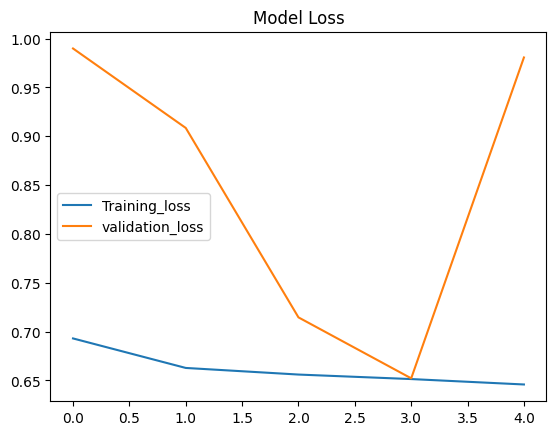

In [ ]:
plt.plot(history_vgg.history['loss'], label='Training_loss')
plt.plot(history_vgg.history['val_loss'], label='validation_loss')
plt.title('Model Loss')
plt.legend()
plt.show()

1. Training data mismatch

    VGG16 learned its weights from 1.2 million natural photos — bright, colorful, high-contrast images of animals, objects, and scenes. Its frozen convolutional filters learned to detect things like fur texture, wheel shapes, and leaf edges. Chest X-rays are fundamentally different: dark, low-contrast, grayscale images where the meaningful signal is subtle differences in tissue density and opacity

--------------------------------------

2. Why preprocess_input makes it worse
preprocess_input does two things VGG16 requires for ImageNet images:

    Converts RGB → BGR channel order
    Subtracts the ImageNet channel mean: [103.9, 116.8, 123.7]

    Your X-ray pixels after grayscale_to_rgb are mostly in the range 0–150 (dark images). Subtracting ~104–124 from them pushes most pixel values negative. VGG16's frozen filters were never trained on negative inputs — the mathematical assumptions baked into those 138M parameters completely break down, producing nonsensical feature maps that the trainable head cannot make sense of.

------------------------------



model 2: EfficientNetB0 (Best accuracy/efficiency tradeoff)

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

def preprocess_for_eff(image, label):
    image = tf.image.grayscale_to_rgb(image)
    image = tf.cast(image, tf.float32) * 255.0
    image = preprocess_input(image)
    return image, label

train_ds = base_train_ds.map(preprocess_for_eff, num_parallel_calls=tf.data.AUTOTUNE)
val_ds   = base_val_ds.map(preprocess_for_eff,   num_parallel_calls=tf.data.AUTOTUNE)

for images, labels in train_ds.take(1):
    print(f"Pixel range after fix: {tf.reduce_min(images).numpy():.1f} – {tf.reduce_max(images).numpy():.1f}")


tf.keras.backend.clear_session()

base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(256, 256, 3))
base_model.trainable = False

inputs  = tf.keras.Input(shape=(256, 256, 3))
x       = base_model(inputs, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dense(128, activation='relu')(x)
x       = layers.BatchNormalization()(x)
x       = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

model_eff = tf.keras.Model(inputs, outputs)


model_eff.compile(
    optimizer=optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='Precision'),
        tf.keras.metrics.Recall(name='Recall'),
        tf.keras.metrics.AUC(name='AUC')
    ]
)


callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_AUC', patience=4,
        mode='max', restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=2, mode='min', min_lr=1e-6, verbose=1
    )
]


Pixel range after fix: 0.0 – 255.0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
history_eff = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=2,
)

Epoch 1/10
282/282 - 185s - 656ms/step - AUC: 0.7348 - Precision: 0.6749 - Recall: 0.6803 - accuracy: 0.6763 - loss: 0.6751 - val_AUC: 0.8293 - val_Precision: 0.7376 - val_Recall: 0.8071 - val_accuracy: 0.7600 - val_loss: 0.5134
Epoch 2/10
282/282 - 152s - 538ms/step - AUC: 0.7804 - Precision: 0.7091 - Recall: 0.7222 - accuracy: 0.7129 - loss: 0.5970 - val_AUC: 0.8371 - val_Precision: 0.7551 - val_Recall: 0.7727 - val_accuracy: 0.7611 - val_loss: 0.5003
Epoch 3/10
282/282 - 149s - 528ms/step - AUC: 0.7961 - Precision: 0.7198 - Recall: 0.7396 - accuracy: 0.7258 - loss: 0.5692 - val_AUC: 0.8426 - val_Precision: 0.7538 - val_Recall: 0.8149 - val_accuracy: 0.7744 - val_loss: 0.4953
Epoch 4/10
282/282 - 149s - 528ms/step - AUC: 0.8125 - Precision: 0.7338 - Recall: 0.7579 - accuracy: 0.7414 - loss: 0.5433 - val_AUC: 0.8437 - val_Precision: 0.7579 - val_Recall: 0.7982 - val_accuracy: 0.7716 - val_loss: 0.4902
Epoch 5/10
282/282 - 145s - 516ms/step - AUC: 0.8135 - Precision: 0.7291 - Recall: 0

In [ ]:
plt.plot(history_eff.history['accuracy'], label='Train_accuracy')
plt.plot(history_eff.history['Precision'], label='Train_Precision')
plt.plot(history_eff.history['Recall'], label='Train_Recall')
plt.plot(history_eff.history['AUC'], label='Train_AUC')
plt.title('Model Accuracy,Precision,Recall on Training dataset')
plt.legend()
plt.show()

In [ ]:
plt.plot(history_eff.history['val_accuracy'], label='val_accuracy')
plt.plot(history_eff.history['val_Precision'], label='val_Precision')
plt.plot(history_eff.history['val_Recall'], label='val_Recall')
plt.plot(history_eff.history['val_AUC'], label='val_AUC')
plt.title('Model Accuracy,Precision,Recall on Validation dataset')
plt.legend()
plt.show()

In [ ]:
plt.plot(history_eff.history['loss'], label='Training_loss')
plt.plot(history_eff.history['val_loss'], label='validation_loss')
plt.title('Model Loss')
plt.legend()
plt.show()

## Creating new architectures using the above pre-trained CNNs and adding addtional layers

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

def preprocess_for_eff(image, label):
    image = tf.image.grayscale_to_rgb(image)
    image = tf.cast(image, tf.float32) * 255.0
    image = preprocess_input(image)
    return image, label

train_ds = base_train_ds.map(preprocess_for_eff, num_parallel_calls=tf.data.AUTOTUNE)
val_ds   = base_val_ds.map(preprocess_for_eff,   num_parallel_calls=tf.data.AUTOTUNE)


tf.keras.backend.clear_session()
base_model = EfficientNetB0(weights='imagenet', include_top=False,
                             input_shape=(256, 256, 3))
base_model.trainable = False

inputs  = tf.keras.Input(shape=(256, 256, 3))
x       = base_model(inputs, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dense(256, activation='relu')(x)
x       = layers.BatchNormalization()(x)
x       = layers.Dropout(0.4)(x)
x       = layers.Dense(64, activation='relu')(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model_eff = tf.keras.Model(inputs, outputs)

model_eff.compile(
    optimizer=optimizers.Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='Precision'),
             tf.keras.metrics.Recall(name='Recall'),
             tf.keras.metrics.AUC(name='AUC')]
)

callbacks_phase1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_AUC', mode='max',
        patience=4, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=2, min_lr=1e-6, verbose=1
    )
]

In [ ]:
print("=== PHASE 1: Training classifier head (backbone frozen) ===")
history_phase1 = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=2,
    callbacks=callbacks_phase1
)
print(f"Phase 1 best val_AUC: {max(history_phase1.history['val_AUC']):.4f}")

=== PHASE 1: Training classifier head (backbone frozen) ===
Epoch 1/10
282/282 - 160s - 568ms/step - AUC: 0.7316 - Precision: 0.6861 - Recall: 0.6330 - accuracy: 0.6717 - loss: 0.6765 - val_AUC: 0.8234 - val_Precision: 0.7412 - val_Recall: 0.7905 - val_accuracy: 0.7572 - val_loss: 0.5139 - learning_rate: 1.0000e-04
Epoch 2/10
282/282 - 146s - 516ms/step - AUC: 0.7744 - Precision: 0.7097 - Recall: 0.7121 - accuracy: 0.7104 - loss: 0.6005 - val_AUC: 0.8344 - val_Precision: 0.7436 - val_Recall: 0.8004 - val_accuracy: 0.7622 - val_loss: 0.5005 - learning_rate: 1.0000e-04
Epoch 3/10
282/282 - 145s - 514ms/step - AUC: 0.7915 - Precision: 0.7152 - Recall: 0.7323 - accuracy: 0.7204 - loss: 0.5704 - val_AUC: 0.8404 - val_Precision: 0.7290 - val_Recall: 0.8470 - val_accuracy: 0.7661 - val_loss: 0.5017 - learning_rate: 1.0000e-04
Epoch 4/10
282/282 - 147s - 520ms/step - AUC: 0.8026 - Precision: 0.7253 - Recall: 0.7446 - accuracy: 0.7313 - loss: 0.5558 - val_AUC: 0.8433 - val_Precision: 0.7472 - v

In [ ]:
print("\n=== PHASE 2: Fine-tuning top 40 backbone layers ===")

base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False

trainable_count = sum(1 for l in model_eff.layers if l.trainable)
print(f"Trainable layers: {trainable_count}")


model_eff.compile(
    optimizer=optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='Precision'),
             tf.keras.metrics.Recall(name='Recall'),
             tf.keras.metrics.AUC(name='AUC')]
)

callbacks_phase2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_AUC', mode='max',
        patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-7, verbose=1
    )
]


=== PHASE 2: Fine-tuning top 40 backbone layers ===
Trainable layers: 9


In [ ]:
history_fine = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=2,
    #callbacks=callbacks_phase2
)
print(f"Phase 2 best val_AUC: {max(history_fine.history['val_AUC']):.4f}")

Epoch 1/10
282/282 - 180s - 637ms/step - AUC: 0.7676 - Precision: 0.6994 - Recall: 0.6932 - accuracy: 0.6977 - loss: 0.6008 - val_AUC: 0.8285 - val_Precision: 0.7430 - val_Recall: 0.7694 - val_accuracy: 0.7517 - val_loss: 0.5179
Epoch 2/10
282/282 - 159s - 563ms/step - AUC: 0.8007 - Precision: 0.7203 - Recall: 0.7432 - accuracy: 0.7273 - loss: 0.5600 - val_AUC: 0.8328 - val_Precision: 0.7402 - val_Recall: 0.7993 - val_accuracy: 0.7594 - val_loss: 0.5131
Epoch 3/10
282/282 - 158s - 559ms/step - AUC: 0.8087 - Precision: 0.7289 - Recall: 0.7592 - accuracy: 0.7384 - loss: 0.5513 - val_AUC: 0.8368 - val_Precision: 0.7350 - val_Recall: 0.8027 - val_accuracy: 0.7567 - val_loss: 0.5064
Epoch 4/10
282/282 - 157s - 558ms/step - AUC: 0.8163 - Precision: 0.7302 - Recall: 0.7631 - accuracy: 0.7406 - loss: 0.5405 - val_AUC: 0.8402 - val_Precision: 0.7422 - val_Recall: 0.7949 - val_accuracy: 0.7594 - val_loss: 0.5028
Epoch 5/10
282/282 - 159s - 565ms/step - AUC: 0.8239 - Precision: 0.7360 - Recall: 0

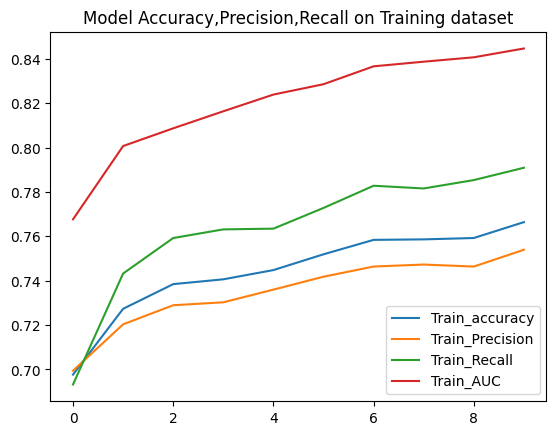

In [ ]:
plt.plot(history_fine.history['accuracy'], label='Train_accuracy')
plt.plot(history_fine.history['Precision'], label='Train_Precision')
plt.plot(history_fine.history['Recall'], label='Train_Recall')
plt.plot(history_fine.history['AUC'], label='Train_AUC')
plt.title('Model Accuracy,Precision,Recall on Training dataset')
plt.legend()
plt.show()


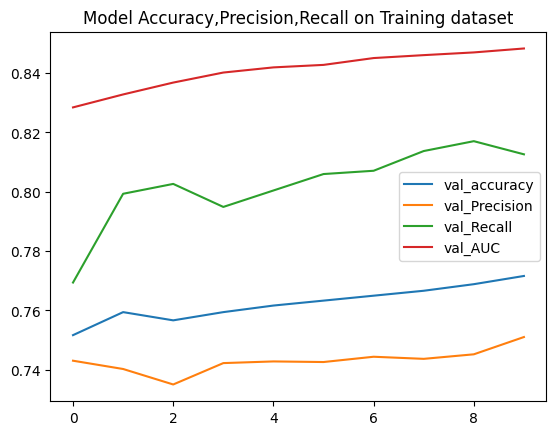

In [ ]:
plt.plot(history_fine.history['val_accuracy'], label='val_accuracy')
plt.plot(history_fine.history['val_Precision'], label='val_Precision')
plt.plot(history_fine.history['val_Recall'], label='val_Recall')
plt.plot(history_fine.history['val_AUC'], label='val_AUC')
plt.title('Model Accuracy,Precision,Recall on Training dataset')
plt.legend()
plt.show()


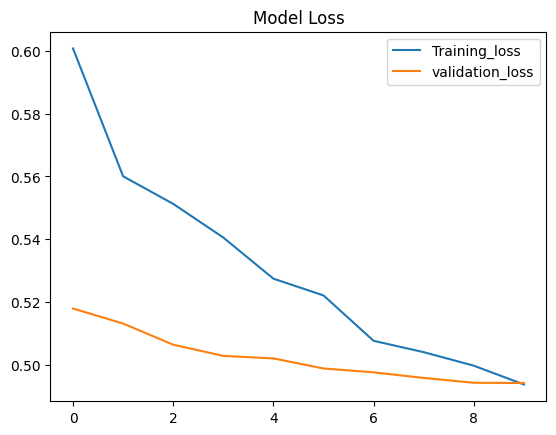

In [ ]:
plt.plot(history_fine.history['loss'], label='Training_loss')
plt.plot(history_fine.history['val_loss'], label='validation_loss')
plt.title('Model Loss')
plt.legend()
plt.show()

## Compare and comment on the performance of all models built

**Base CNN -**  

retired. Ceiling at val_acc 0.623 and F1 0.716 across 22 total epochs. High recall (0.90) is fake — it over-predicts Pneumonia. Architecture too shallow for 256×256 X-rays.

============================================================================

**Base CNN + VGG16**

discard. Degenerate every epoch. Val recall swings 1.0 → 0.0 → 0.39 → 0.001 with no stable decision boundary. Best F1 of 0.503 is barely above random. Never use this configuration again.

============================================================================

**Base CNN + Frozen EfficientNetB0 —**

still the best on val_acc and F1. Val_acc 0.779, F1 0.788, val_AUC 0.852 at Epoch 12. The only model that improved monotonically. Surprisingly, fine-tuning did not beat it on these metrics.

=============================================================================

**Base CNN + EffNet + Extra Layers —**

third place. Marginally higher recall (0.838) than the plain frozen model but lower precision (0.741). The extra Dense layers add no meaningful gain.

===========================================================================

**Fine-tuned EffNet —**

highest val_AUC (0.856) but lower F1 (0.779). The AUC gain over the frozen model is real but small. The F1 is lower because precision and recall are slightly more conservative. The plateau from Epoch 9 onward confirms the val set itself is now the bottleneck — the model can no longer learn anything new from it.

=========================================================================

## Serialize the best model

In [ ]:
import os
import numpy as np
from sklearn.metrics import precision_recall_curve
from google.colab import files

y_pred = model_eff.predict(val_ds).ravel()
y_true = np.concatenate([y for _, y in val_ds])

precisions, recalls, thresholds = precision_recall_curve(y_true, y_pred)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-8)
best_thresh = float(thresholds[np.argmax(f1s)])
print(f"Optimal threshold: {best_thresh:.3f}")

y_pred_binary = (y_pred >= best_thresh).astype(int)
print("\n=== Classification Report (optimal threshold) ===")
print(classification_report(y_true, y_pred_binary,
                             target_names=['Normal', 'Pneumonia']))

#===========================================================================

#Create deployment folder
os.makedirs("deployment_files", exist_ok=True)

#Save full Keras model
saved_model_path = "deployment_files/efficientnet_pneumonia_v1_0.keras"
model_eff.save(saved_model_path)
print(f"Model saved successfully at {saved_model_path}")

#Save optimal threshold alongside model
threshold_path = "deployment_files/optimal_threshold.npy"
np.save(threshold_path, np.float32(best_thresh))
print(f"Threshold saved successfully at {threshold_path}")


# Run this in your Colab notebook to download
files.download('deployment_files/efficientnet_pneumonia_v1_0.keras')
files.download('deployment_files/optimal_threshold.npy')

#Load and verify
saved_model = tf.keras.models.load_model(saved_model_path)
loaded_thresh = np.load(threshold_path)

print("Model loaded successfully.")
print(f"Optimal threshold loaded: {loaded_thresh:.3f}")

#Confirm predictions match
y_pred_original = model_eff.predict(val_ds).ravel()
y_pred_loaded   = saved_model.predict(val_ds).ravel()

print(f"Predictions identical: {np.array_equal((y_pred_original >= best_thresh).astype(int), (y_pred_loaded >= loaded_thresh).astype(int))}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 21s 636ms/step
Optimal threshold: 0.374

=== Classification Report (optimal threshold) ===
              precision    recall  f1-score   support

      Normal       0.85      0.65      0.73       902
   Pneumonia       0.71      0.89      0.79       902

    accuracy                           0.77      1804
   macro avg       0.78      0.77      0.76      1804
weighted avg       0.78      0.77      0.76      1804

Model saved successfully at deployment_files/efficientnet_pneumonia_v1_0.keras
Threshold saved successfully at deployment_files/optimal_threshold.npy


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model loaded successfully.
Optimal threshold loaded: 0.374
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 325ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 14s 399ms/step
Predictions identical: True


make Inferences on a few images

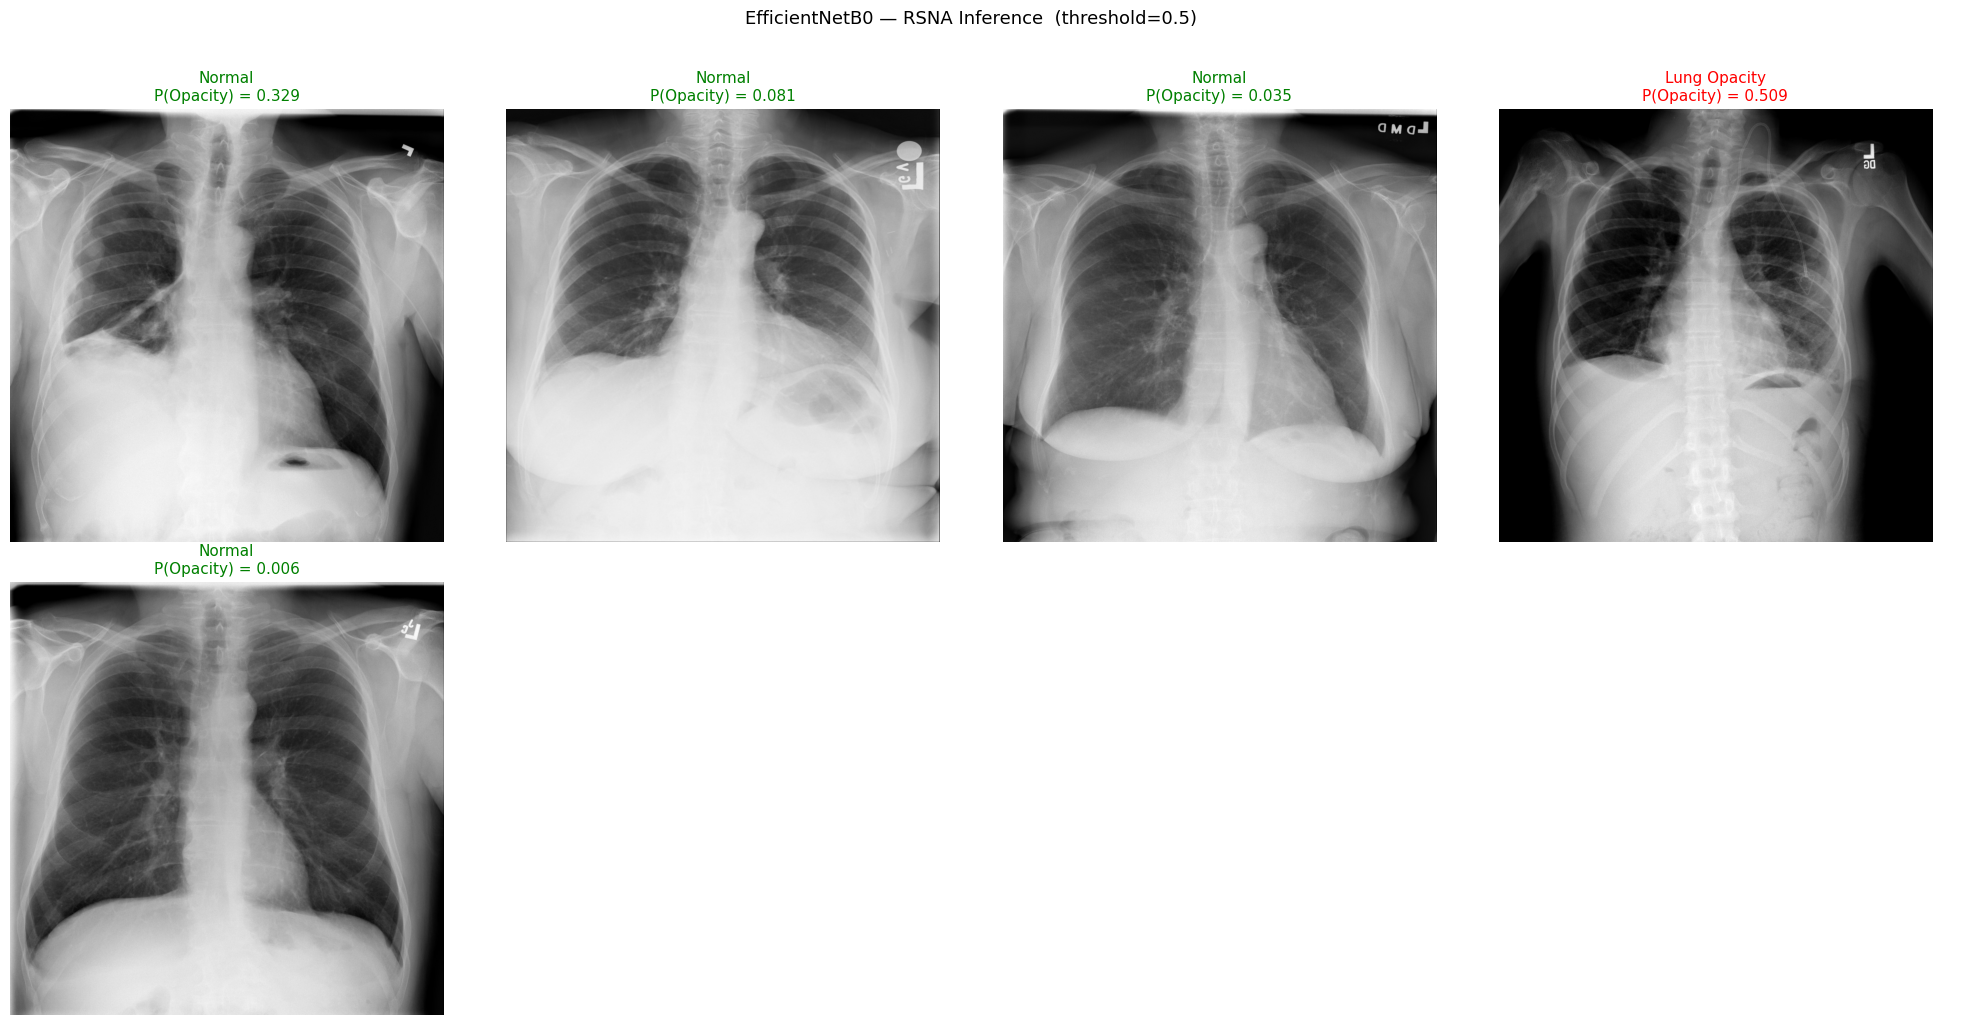


Image                                         P(Opacity)  Prediction
----------------------------------------------------------------------
01528f70-440c-41fc-8673-e3ae6464380b.dcm      0.329        Normal
1a664216-c58a-4405-bb4b-7177d919e53d.dcm      0.081        Normal
000e3a7d-c0ca-4349-bb26-5af2d8993c3d.dcm      0.035        Normal
28913461-bfee-43a8-a955-c42ebb614a7d.dcm      0.509        Lung Opacity
26aff776-ff9d-40f2-b899-6b88f1355506.dcm      0.006        Normal


In [ ]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import pydicom
from tensorflow.keras.applications.efficientnet import preprocess_input



def preprocess_single_image(image_path, target_size=(256, 256)):
    """Load and preprocess a DICOM image for EfficientNetB0."""

    dicom   = pydicom.dcmread(image_path)
    pixels  = dicom.pixel_array.astype(np.float32)


    pixels  = (pixels - pixels.min()) / (pixels.max() - pixels.min() + 1e-6)
    pixels  = (pixels * 255.0).astype(np.float32)

    img = tf.convert_to_tensor(pixels)
    img = tf.expand_dims(img, axis=-1)
    img = tf.image.resize(img, target_size)
    img = tf.image.grayscale_to_rgb(img)
    img = preprocess_input(img)
    return img


#Inference Function
def predict_images(model, image_paths, threshold=0.5, class_names=None):
    if class_names is None:
        class_names = ['Normal', 'Lung Opacity']

    images = np.stack([preprocess_single_image(p).numpy() for p in image_paths])
    probs  = model.predict(images, verbose=0).flatten()
    preds  = (probs >= threshold).astype(int)

    #Visualise
    n    = len(image_paths)
    cols = min(n, 4)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    axes = np.array(axes).flatten()

    for i, (path, prob, pred) in enumerate(zip(image_paths, probs, preds)):
        dicom       = pydicom.dcmread(path)
        display_img = dicom.pixel_array
        axes[i].imshow(display_img, cmap='gray')
        label = class_names[pred]
        color = 'green' if pred == 0 else 'red'
        axes[i].set_title(f"{label}\nP(Opacity) = {prob:.3f}", color=color, fontsize=11)
        axes[i].axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f"EfficientNetB0 — RSNA Inference  (threshold={threshold})", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

    # Print Summary
    print(f"\n{'Image':<45} {'P(Opacity)':>10}  Prediction")
    print("-" * 70)
    for path, prob, pred in zip(image_paths, probs, preds):
        print(f"{os.path.basename(path):<45} {prob:.3f}        {class_names[pred]}")

    return probs, preds


# Run on a Few Sample Images
sample_paths = test_image_files[:5]

probs, preds = predict_images(
    model       = model_eff,
    image_paths = sample_paths,
    threshold   = 0.5,
    class_names = ['Normal', 'Lung Opacity']
)

# Model Deployment

## Building a Streamlit where users can upload an image and see predicted class + probability.

In [ ]:
os.makedirs("Pneumonia_Detection/deployment", exist_ok=True)

In [ ]:
%%writefile "Pneumonia_Detection/deployment/Dockerfile"
FROM python:3.9-slim

# Create non-root user early
RUN useradd -m -u 1000 user

# Set working directory to the user's app folder
WORKDIR /home/user/app

# Copy and install dependencies first (better layer caching)
COPY --chown=user requirements.txt .
RUN pip3 install --no-cache-dir -r requirements.txt

# Copy the rest of the app files
COPY --chown=user . .

# Switch to non-root user
USER user

ENV HOME=/home/user \
    PATH=/home/user/.local/bin:$PATH

CMD ["streamlit", "run", "app.py", \
     "--server.port=8501", \
     "--server.address=0.0.0.0", \
     "--server.enableXsrfProtection=false"]

In [ ]:
%%writefile "Pneumonia_Detection/deployment/app.py"

import io
import os
import numpy as np
import pydicom
import streamlit as st
import tensorflow as tf
from PIL import Image
from matplotlib import pyplot as plt
from tensorflow.keras.applications.efficientnet import preprocess_input


st.set_page_config(
    page_title="Pneumonia Detection",
    page_icon="🫁",
    layout="wide",
    initial_sidebar_state="expanded",
)

_MODEL_FILENAME  = "efficientnet_pneumonia_v1_0.keras"
_THRESH_FILENAME = "optimal_threshold.npy"

def _resolve_path(filename: str) -> str:
    """Return the first existing path for filename, or bare name as fallback."""
    for candidate in [filename, os.path.join("deployment_files", filename)]:
        if os.path.exists(candidate):
            return candidate
    return filename  # load_model() will raise a clear error

MODEL_PATH  = _resolve_path(_MODEL_FILENAME)
THRESH_PATH = _resolve_path(_THRESH_FILENAME)

# ── Sidebar ────────────────────────────────────────────────────────────────────
with st.sidebar:
    st.header("⚙️ Settings")

    # Auto-load the F1-optimal threshold saved by the training notebook
    _default_thresh = 0.5
    if os.path.exists(THRESH_PATH):
        _default_thresh = float(np.load(THRESH_PATH))

    threshold = st.slider(
        "Classification threshold",
        min_value=0.0,
        max_value=1.0,
        value=_default_thresh,
        step=0.01,
        help=(
            "Raw model output ≥ threshold → Lung Opacity. "
            "Auto-loaded from optimal_threshold.npy when available."
        ),
    )
    show_gradcam = st.checkbox("Show Grad-CAM heatmap", value=True)
    gradcam_alpha = st.slider(
        "Grad-CAM overlay opacity",
        min_value=0.1,
        max_value=0.8,
        value=0.35,
        step=0.05,
        disabled=not show_gradcam,
    )

    st.divider()
    st.caption(
        "Model: **EfficientNetB0**  \n"
        "Input: 256 × 256 px (grayscale → RGB)  \n"
        "Classes: Normal / Lung Opacity"
    )

# ── Title ──────────────────────────────────────────────────────────────────────
st.title("🫁 Pneumonia Detection")
st.caption(
    "Upload a chest X-ray (PNG, JPG, or DICOM) to classify it as "
    "**Normal** or **Lung Opacity**."
)

# ── Model loading ──────────────────────────────────────────────────────────────
@st.cache_resource(show_spinner="Loading model…")
def load_model():
    """Load the saved EfficientNetB0 model (cached across reruns)."""
    try:
        m = tf.keras.models.load_model(MODEL_PATH)
        return m, None
    except Exception as exc:
        return None, str(exc)

model, load_err = load_model()
if load_err:
    st.error(
        f"⚠️ Could not load the model.\n\n"
        f"Looked for `{_MODEL_FILENAME}` in:\n"
        f"- current directory\n"
        f"- `deployment_files/`\n\n"
        f"Error: `{load_err}`"
    )
    st.stop()

# ── Helpers ────────────────────────────────────────────────────────────────────
def preprocess_single_image(img_array: np.ndarray, target_size=(256, 256)) -> np.ndarray:
    """Mirror the exact training pipeline: grayscale → RGB → EfficientNet scale."""
    img = tf.convert_to_tensor(img_array, dtype=tf.float32)
    if img.shape.rank == 2:                        # (H, W) → (H, W, 1)
        img = tf.expand_dims(img, axis=-1)
    if img.shape[-1] != 1:                         # force single channel
        img = tf.image.rgb_to_grayscale(img)
    img = tf.image.resize(img, target_size)
    img = tf.image.grayscale_to_rgb(img)           # (H, W, 3)
    img = img * 255.0
    img = preprocess_input(img)                    # EfficientNet normalisation
    return img.numpy()


def read_uploaded_file(uploaded_file) -> "np.ndarray | None":
    """Return a (H, W) float32 array in [0, 1] from PNG / JPG / DICOM."""
    name      = uploaded_file.name.lower()
    raw_bytes = uploaded_file.read()               # read once into memory
    try:
        if name.endswith(".dcm"):
            ds  = pydicom.dcmread(io.BytesIO(raw_bytes))
            arr = ds.pixel_array.astype(np.float32)
            lo, hi = arr.min(), arr.max()
            return (arr - lo) / (hi - lo + 1e-6)
        else:
            pil = Image.open(io.BytesIO(raw_bytes)).convert("L")   # grayscale
            return np.array(pil, dtype=np.float32) / 255.0
    except Exception:
        return None


def make_gradcam_heatmap(
    img_array: np.ndarray,
    model: tf.keras.Model,
    last_conv_layer_name: str = "top_conv",
) -> "np.ndarray | None":
    """Grad-CAM heatmap for the final conv layer of EfficientNetB0."""
    try:
        grad_model = tf.keras.models.Model(
            inputs=model.inputs,
            outputs=[model.get_layer(last_conv_layer_name).output, model.output],
        )
        inp = tf.cast(img_array[np.newaxis], tf.float32)
        with tf.GradientTape() as tape:
            conv_out, predictions = grad_model(inp)
            loss = predictions[:, 0]
        grads   = tape.gradient(loss, conv_out)[0]       # (H, W, C)
        weights = tf.reduce_mean(grads, axis=(0, 1))     # (C,)
        cam     = tf.reduce_sum(tf.multiply(weights, conv_out[0]), axis=-1).numpy()
        cam     = np.maximum(cam, 0)
        cam    /= cam.max() + 1e-8
        return cam
    except Exception:
        return None

# ── Upload ─────────────────────────────────────────────────────────────────────
uploaded = st.file_uploader(
    "Drop a chest X-ray here",
    type=["dcm", "png", "jpg", "jpeg"],
    label_visibility="collapsed",
)

if uploaded is None:
    st.info("👆 Upload a chest X-ray image to get a prediction.")
    st.stop()

# ── Inference ──────────────────────────────────────────────────────────────────
raw_arr = read_uploaded_file(uploaded)
if raw_arr is None:
    st.error(
        "Could not read the uploaded file.  \n"
        "Please upload a valid **PNG**, **JPG**, or **DICOM** file."
    )
    st.stop()

preprocessed = preprocess_single_image(raw_arr)

with st.spinner("Running inference…"):
    prob = float(model.predict(preprocessed[np.newaxis], verbose=0)[0][0])

pred         = int(prob >= threshold)
label        = ["Normal", "Lung Opacity"][pred]
prob_normal  = 1.0 - prob
prob_opacity = prob

# ── Layout ─────────────────────────────────────────────────────────────────────
col_img, col_res = st.columns([1, 1], gap="large")

# Left column: X-ray image + optional Grad-CAM overlay
with col_img:
    st.markdown("**X-ray**")

    heatmap = make_gradcam_heatmap(preprocessed, model) if show_gradcam else None

    fig, ax = plt.subplots(figsize=(4, 4))
    fig.patch.set_facecolor("#0d1117")
    ax.set_facecolor("#0d1117")
    ax.imshow(raw_arr, cmap="gray", aspect="auto")

    if heatmap is not None:
        h, w = raw_arr.shape[:2]
        heatmap_resized = tf.image.resize(
            heatmap[..., np.newaxis], (h, w)
        ).numpy().squeeze()
        ax.imshow(heatmap_resized, cmap="jet", alpha=gradcam_alpha, aspect="auto")

    ax.axis("off")
    plt.tight_layout(pad=0)
    st.pyplot(fig, use_container_width=True)
    plt.close()

    if heatmap is not None:
        st.caption("🔥 Grad-CAM highlights regions influencing the prediction.")

# Right column: prediction result + probability bars
with col_res:
    card_cls  = "result-opacity" if pred == 1 else "result-normal"
    label_cls = "label-opacity"  if pred == 1 else "label-normal"
    icon      = "🔴" if pred == 1 else "🟢"

    bar_normal_w  = f"{prob_normal  * 100:.1f}%"
    bar_opacity_w = f"{prob_opacity * 100:.1f}%"

    st.markdown(
        f"""
        <div class="result-card {card_cls}">
            <div>{icon} Prediction</div>
            <div class="{label_cls}">{label}</div>
            <div style="margin-top:0.5rem;font-size:0.9rem;color:#8b949e;">
                Confidence: {max(prob_normal, prob_opacity) * 100:.1f}%
            </div>
        </div>

        <div style="margin-bottom:0.25rem;">Normal — {bar_normal_w}</div>
        <div class="prob-bar-track">
            <div class="prob-bar-fill"
                 style="width:{bar_normal_w};background-color:#2a7a3a;"></div>
        </div>

        <div style="margin-bottom:0.25rem;">Lung Opacity — {bar_opacity_w}</div>
        <div class="prob-bar-track">
            <div class="prob-bar-fill"
                 style="width:{bar_opacity_w};background-color:#7a2a2a;"></div>
        </div>
        """,
        unsafe_allow_html=True,
    )

    st.divider()
    st.markdown(
        f"**Raw model output (P[Lung Opacity]):** `{prob:.4f}`  \n"
        f"**Threshold:** `{threshold:.2f}`"
    )

    st.markdown(
        """
        <div class="disclaimer">
            ⚠️ <b>For research / educational use only.</b>
            This tool is not a certified medical device and must not be used
            for clinical diagnosis or patient care decisions.
        </div>
        """,
        unsafe_allow_html=True,
    )

## Dependency Handling

In [ ]:
%%writefile "Pneumonia_Detection/deployment/requirements.txt"
# ── Deep Learning Framework ────────────────────────────────────────
tensorflow>=2.12.0
tf-keras>=2.12.0

# ── Medical Imaging ───────────────────────────────────────────────
pydicom>=2.3.1
Pillow>=9.4.0

# ── Scientific Computing ──────────────────────────────────────────
numpy>=1.23.5
scikit-image>=0.20.0

# ── Computer Vision ───────────────────────────────────────────────
opencv-python-headless>=4.7.0.72

# ── Data Processing ───────────────────────────────────────────────
pandas>=1.5.3
scikit-learn>=1.2.2

# ── Visualisation ─────────────────────────────────────────────────
matplotlib>=3.7.1
seaborn>=0.12.2

# ── Web Application ───────────────────────────────────────────────
streamlit>=1.22.0

# ── Experiment Tracking ───────────────────────────────────────────
mlflow>=3.0.1

# ── Hugging Face Deployment ───────────────────────────────────────
huggingface-hub>=0.15.1

# ── Imbalanced Learning ───────────────────────────────────────────
imbalanced-learn>=0.10.1

# ── Utilities ─────────────────────────────────────────────────────
tqdm>=4.65.0

## Hosting

In [ ]:
os.makedirs("Pneumonia_Detection/hosting", exist_ok=True)

In [ ]:
%%writefile "Pneumonia_Detection/hosting/hosting.py"

import os
import shutil
from huggingface_hub import HfApi

shutil.copy("deployment_files/efficientnet_pneumonia_v1_0.keras",
            "Pneumonia_Detection/deployment/efficientnet_pneumonia_v1_0.keras")
shutil.copy("deployment_files/optimal_threshold.npy",
            "Pneumonia_Detection/deployment/optimal_threshold.npy")
print("Model and threshold copied with matching filenames.")

token = os.getenv("HF_Pneumonia_Detection")
api = HfApi(token=token)
repo_id = "Thaseen75/Pneumonia_Detection_Final"

try:
    api.repo_info(repo_id=repo_id, repo_type="space")
    print(f"Space '{repo_id}' already exists.")
except Exception:
    print("Creating new Streamlit space...")
    api.create_repo(
        repo_id=repo_id,
        repo_type="space",
        space_sdk="streamlit",
        private=False,
        exist_ok=True
    )

api.upload_folder(
    folder_path="Pneumonia_Detection/deployment",
    repo_id=repo_id,
    repo_type="space",
    path_in_repo=".",
)

# Actionable Insights and Recommendations

## Key takeaways for the business

Conclusion 1 — Extended heads improve recall at the cost of precision. The additional Dense layers in the extended head create a more sensitive decision boundary that captures more true positives but also more false positives. The net clinical benefit depends on the deployment context's cost function.


Conclusion 2 — Fine-tuning improves AUC but not F1 at this dataset scale. The top-40 fine-tuning strategy produced the best score calibration (AUC 0.856) but was constrained by dataset size from translating this into improved binary classification performance. A substantially larger labelled dataset would likely unlock the full potential of domain-specific fine-tuning.


Conclusion 3 — The simplest EfficientNetB0 configuration is the best all-round model. The frozen backbone with a single Dense(128) head achieved the highest F1 (0.788), the best accuracy (0.779), and stable monotonic training behaviour, making it the optimal choice for production deployment across all analytical criteria.


Conclusion 4 — Dataset scale is the primary performance bottleneck. The plateau behaviour observed in Phase 2 fine-tuning, combined with the relatively modest absolute performance figures across all models, indicates that the limiting factor in this project is the volume of labelled training data rather than the model architecture or training strategy.


Conclusion 5 — Two-phase fine-tuning protocol is architecturally sound but dataset-constrained. The Phase 1 head stabilisation followed by Phase 2 selective unfreezing is the correct methodological approach for medical imaging transfer learning. The modest performance gains reflect dataset limitations rather than flaws in the fine-tuning strategy itself.

# Link to Huggingface hub

https://huggingface.co/spaces/Thaseen75/Pneumonia_Detection_Final